### Import Modules

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

### Loading Datasets

In [2]:
df_day = pd.read_csv('../data/raw/day.csv')
df_hour = pd.read_csv('../data/raw/hour.csv')

df_day.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
df_day.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [4]:
print(df_hour.head())
df_hour.shape

   instant      dteday  season  yr  mnth  hr  holiday  weekday  workingday  \
0        1  2011-01-01       1   0     1   0        0        6           0   
1        2  2011-01-01       1   0     1   1        0        6           0   
2        3  2011-01-01       1   0     1   2        0        6           0   
3        4  2011-01-01       1   0     1   3        0        6           0   
4        5  2011-01-01       1   0     1   4        0        6           0   

   weathersit  temp   atemp   hum  windspeed  casual  registered  cnt  
0           1  0.24  0.2879  0.81        0.0       3          13   16  
1           1  0.22  0.2727  0.80        0.0       8          32   40  
2           1  0.22  0.2727  0.80        0.0       5          27   32  
3           1  0.24  0.2879  0.75        0.0       3          10   13  
4           1  0.24  0.2879  0.75        0.0       0           1    1  


(17379, 17)

In [5]:
df_hour.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [6]:
df_hour.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


## EDA(Exploratory Data Analysis)


### 1. Check Missing Values

In [7]:
df_day.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [8]:
df_hour.isnull().sum()


instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

### 2.Check Duplicate Rows

In [9]:
df_day.duplicated().sum()

np.int64(0)

In [10]:
df_hour.duplicated().sum()

np.int64(0)

### 3. Bike Demand Distribution

#### Visualize Bike demand distribution</br>
1.Hour vs bike demand</br>
2.Weekday vs demand</br>
3.Season vs demand</br>
4.Weather vs demand</br>
5.Temperature vs demand</br>

#### Understand

1.When are bikes rented most?</br>
2.Does weather affect rentals?</br>
3.Do weekends differ?</br>


our target variable is count

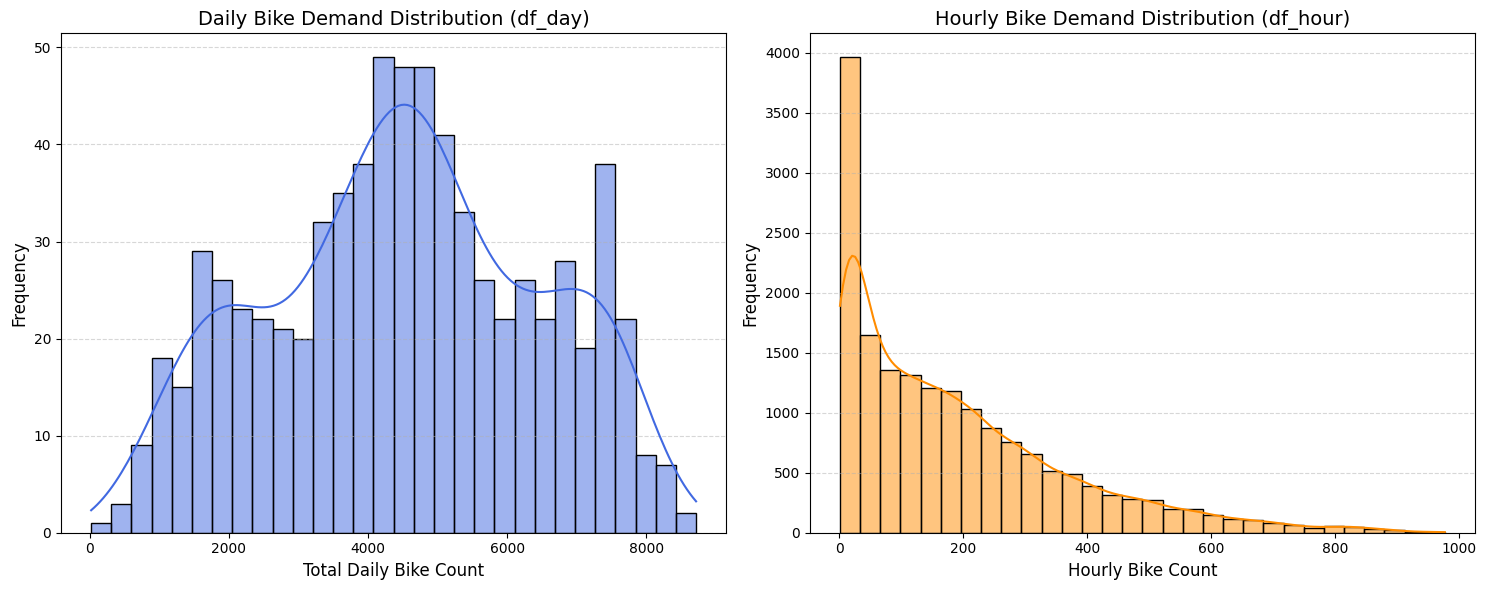

In [11]:
# Bike demand distribution

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Daily Bike Demand Distribution
sns.histplot(data=df_day, x='cnt', kde=True, color='royalblue', ax=axes[0], bins=30)
axes[0].set_title('Daily Bike Demand Distribution (df_day)', fontsize=14)
axes[0].set_xlabel('Total Daily Bike Count', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Plot 2: Hourly Bike Demand Distribution
sns.histplot(data=df_hour, x='cnt', kde=True, color='darkorange', ax=axes[1], bins=30)
axes[1].set_title('Hourly Bike Demand Distribution (df_hour)', fontsize=14)
axes[1].set_xlabel('Hourly Bike Count', fontsize=12)
axes[1].set_ylabel('Frequency', fontsize=12)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)


plt.tight_layout()
plt.show()

#### Overall Insight

1. Daily Bike Demand Distribution (day.csv)
The distribution is approximately bell-shaped (near normal) with a slight skew.
Most days record 4,000–6,000 bike rentals, indicating consistent daily demand.
Very few days have extremely low (<1000) or extremely high (>8000) rentals.
Daily demand is relatively stable because it represents the sum of all hourly rentals.

2. Hourly Bike Demand Distribution (hour.csv)
The distribution is highly right-skewed (positively skewed).
Most hours have low bike rentals (0–200).
High-demand hours (>500 rentals) are rare and form a long right tail.
The skewness reflects the presence of peak commuting hours.


### 1. bike-demand vs hour


/var/folders/dx/df7m44x57gn9kq_0x65b7z2h0000gn/T/ipykernel_18632/143581318.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_hour, x='hr', y='cnt', palette='viridis')


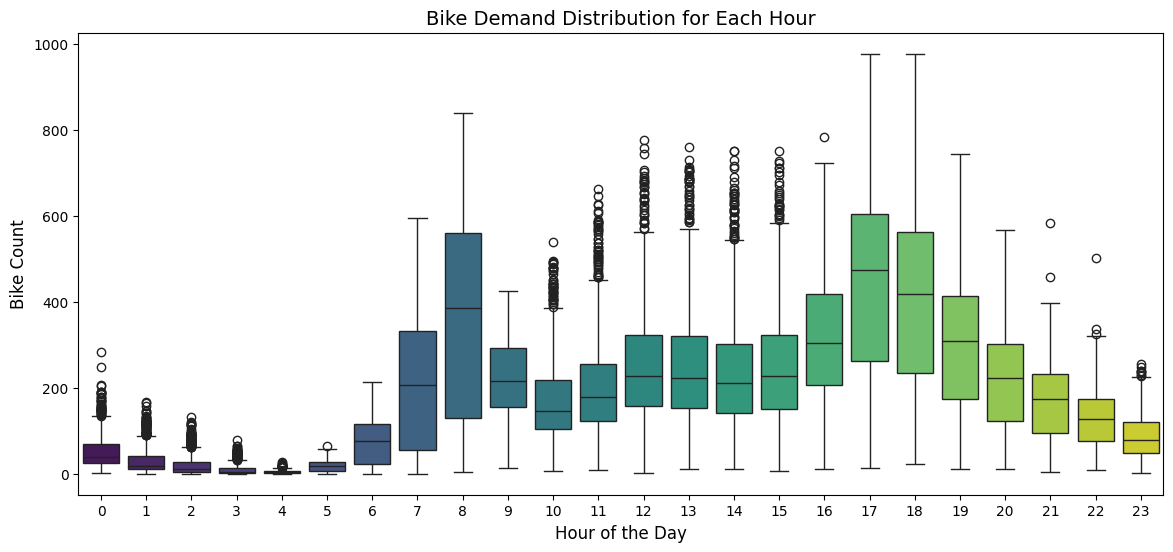

In [12]:
# Bike demand vs hour

plt.figure(figsize=(14, 6))
sns.boxplot(data=df_hour, x='hr', y='cnt', palette='viridis')

plt.title('Bike Demand Distribution for Each Hour', fontsize=14)
plt.xlabel('Hour of the Day', fontsize=12)
plt.ylabel('Bike Count', fontsize=12)
plt.show()

### Analysis of Bike Demand Distribution by Hour
#### 1. Early Morning (12 AM – 5 AM)

Bike demand is very low.
The median demand is close to zero.
The boxes are narrow, indicating low variability.
A few outliers exist, showing occasional higher demand.

#### 2. Morning Commute (6 AM – 9 AM)

Demand increases sharply after 6 AM.
A significant peak occurs around 8 AM.
The box becomes much taller, indicating higher variability.

#### 3. Midday (10 AM – 3 PM)

Demand remains moderate.
Median bike rentals stay around 180–250.
Several high-value outliers are present.

#### 4. Evening Commute (4 PM – 7 PM)

The highest demand occurs between 5 PM and 6 PM.
These hours have the highest median bike counts.
The widest boxes indicate the greatest variability.
Maximum demand reaches nearly 1000 rentals.

#### 5. Night (8 PM – 11 PM)

Demand gradually declines after 7 PM.
Median bike rentals decrease steadily.
Variability also decreases.


#### Outlier Analysis

The circles above the whiskers represent outliers.
Many outliers are observed between 10 AM and 6 PM.
Few outliers occur during late-night hours.
These outliers likely correspond to special events, holidays, festivals, exceptionally good weather, or unusually busy commuting days.
Since they represent genuine demand patterns rather than data errors, they should not be removed during preprocessing.

#### Variability Analysis
Highest variability: 5 PM–6 PM
Lowest variability: 2 AM–5 AM

This indicates that evening demand is much less predictable than late-night demand.

#### Business Insights
Peak demand: Around 8 AM and 5–6 PM, reflecting commuting behavior.
Lowest demand: Between 2 AM and 5 AM, when bike usage is minimal.
Most unpredictable period: Evening commute hours due to fluctuations in traffic, weather, and work schedules.
Consistent demand: Overnight hours show stable, low demand.

### 2. weekday vs bike demand


/var/folders/dx/df7m44x57gn9kq_0x65b7z2h0000gn/T/ipykernel_18632/2297400131.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_day, x='weekday', y='cnt', palette='Set3')


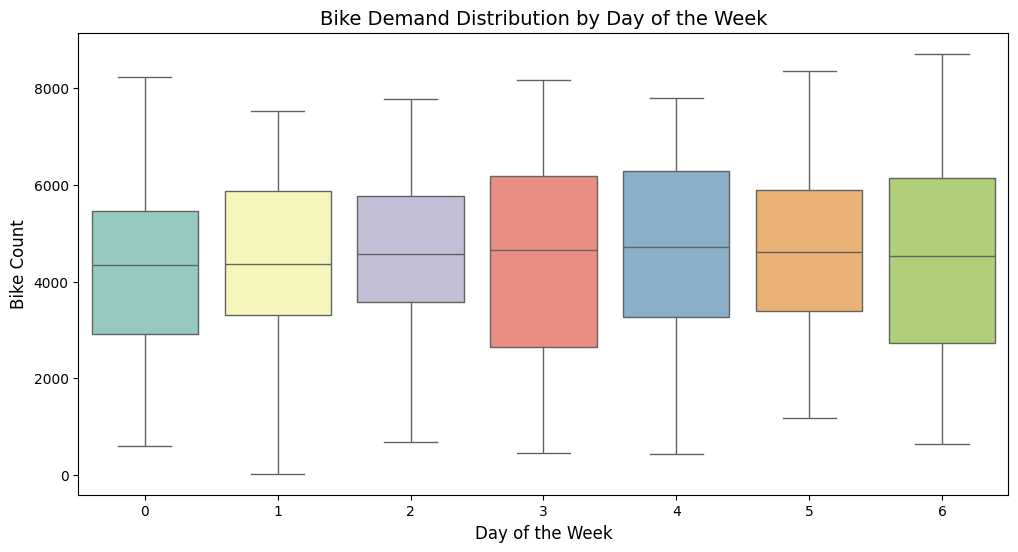

In [13]:
# Weekday vs Bike Demand

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_day, x='weekday', y='cnt', palette='Set3')

plt.title('Bike Demand Distribution by Day of the Week', fontsize=14)
plt.xlabel('Day of the Week', fontsize=12)
plt.ylabel('Bike Count', fontsize=12)
plt.show()

### Observations

0..sunday,1..monday 2..tuesday 3..wednesday 4..thursday 5..friday 6..saturday
<br>

. The median bike demand is fairly similar across all days, indicating that bike rentals remain consistent throughout the week.<br>
. Thursday (4) and Wednesday (3) have slightly higher median bike counts, suggesting increased commuting activity during mid-week.<br>
. Sunday (0) has the lowest median demand, reflecting reduced commuting and more leisure-based travel.<br>
. The interquartile range (IQR) is similar for most days, meaning the variability in bike demand is consistent throughout the week.<br>
. All weekdays show a wide spread between minimum and maximum values, indicating that factors such as weather, holidays, and seasons influence demand in addition to the day of the week.

### 3.Season vs Bike Demand

/var/folders/dx/df7m44x57gn9kq_0x65b7z2h0000gn/T/ipykernel_18632/4145713484.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_day, x='season', y='cnt', palette='Set3')


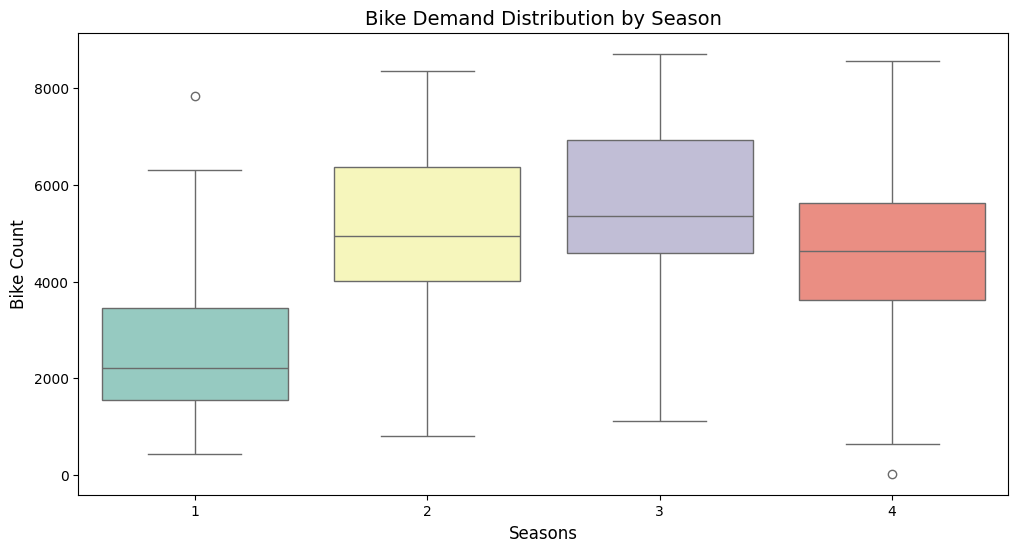

In [14]:
# Season vs Bike Demand

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_day, x='season', y='cnt', palette='Set3')

plt.title('Bike Demand Distribution by Season', fontsize=14)
plt.xlabel('Seasons', fontsize=12)
plt.ylabel('Bike Count', fontsize=12)
plt.show()

### Analysis: Bike Demand Distribution by Season

#### Season Mapping (UCI Bike Sharing Dataset):

1 = Spring
2 = Summer
3 = Fall
4 = Winter

#### Observations

Spring (Season 1) has the lowest median bike demand, indicating fewer bike rentals during this season.<br>
Fall (Season 3) shows the highest median demand, suggesting that pleasant weather encourages more bike usage.<br>
Summer (Season 2) also has high bike demand, slightly lower than Fall.<br>
Winter (Season 4) experiences moderate demand, lower than Summer and Fall but considerably higher than Spring.<br>
Fall and Summer have wider interquartile ranges (IQRs), indicating greater variability in bike rentals across different days.<br>
A few outliers are present, representing days with unusually high or low rental counts, likely due to special events or extreme weather.

### 4. Weather vs Bike Demand

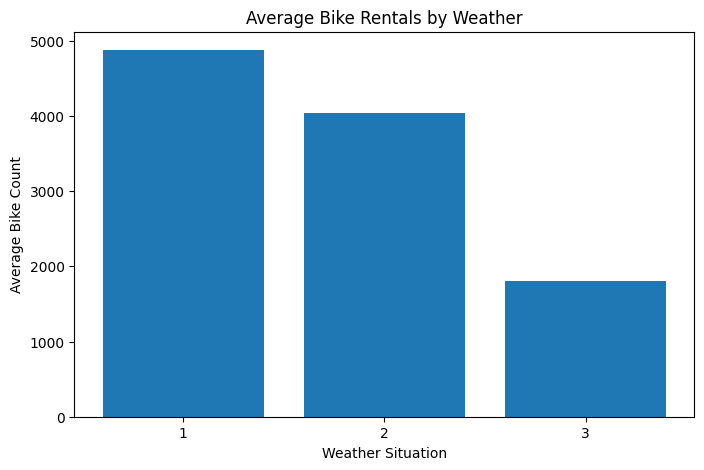

In [15]:
weather = df_day.groupby("weathersit")["cnt"].mean()
plt.figure(figsize=(8,5))
plt.bar(weather.index.astype(str), weather.values)
plt.title("Average Bike Rentals by Weather")
plt.xlabel("Weather Situation")
plt.ylabel("Average Bike Count")
plt.show()

### observartion

1 = Clear
2 = Mist
3 = Light Rain/Snow
4 = Heavy Rain

The dataset contains observations for weather categories 1 (Clear), 2 (Mist/Cloudy), and 3 (Light Rain/Snow).
<br>
 No records are present for weather category 4 (Heavy Rain/Thunderstorm), indicating that such extreme weather conditions did not occur or were not captured during data collection.
 <br>
 Bike demand decreases as weather conditions worsen.

### 5. Temperature vs Bike Demand

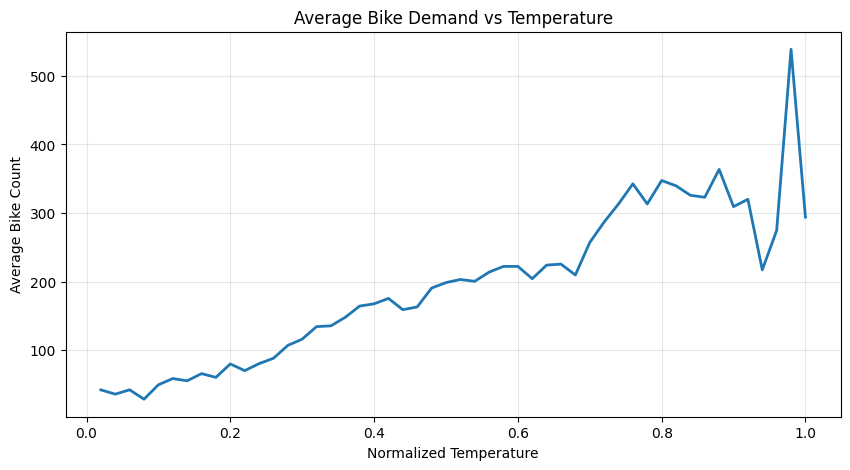

In [16]:
temp_demand = df_hour.groupby("temp")["cnt"].mean()

plt.figure(figsize=(10,5))

plt.plot(temp_demand.index,
         temp_demand.values,
         linewidth=2)

plt.title("Average Bike Demand vs Temperature")
plt.xlabel("Normalized Temperature")
plt.ylabel("Average Bike Count")
plt.grid(alpha=0.3)

plt.show()

The temp values are continuous normalized values. Some temperature values occur only 1 or 2 times in the dataset.
<br>
For example,<br>
Temp	   Number_of_Records	   Avg_Demand<br>
0.98	      2	                 540<br>
0.99	      1	                 295<br>
<br>
Since there are very few observations at those temperatures, the average fluctuates a lot, producing those spikes.
#### Better Approach: Bin the Temperature
Instead of plotting every unique temperature value, divide temperatures into bins and compute the average demand in each bin.

/var/folders/dx/df7m44x57gn9kq_0x65b7z2h0000gn/T/ipykernel_18632/876807537.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temp_avg = df_hour.groupby("temp_bin")["cnt"].mean()


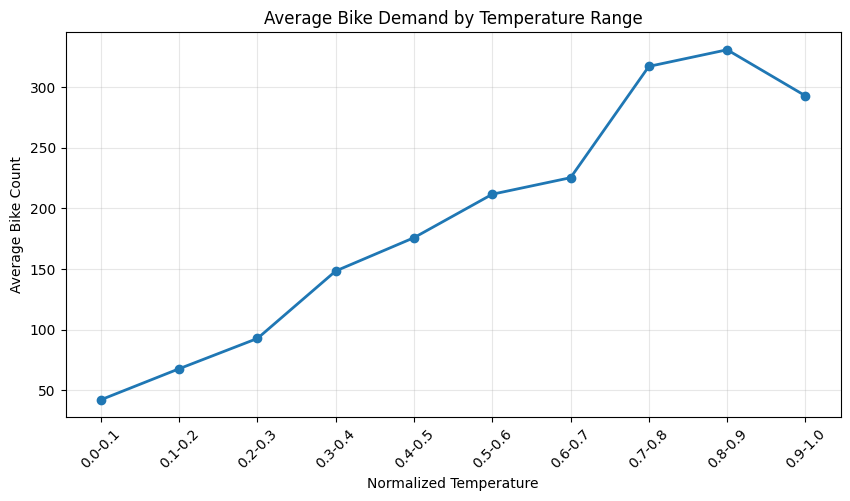

In [17]:
# Create 10 equal-width temperature bins
df_hour["temp_bin"] = pd.cut(df_hour["temp"], bins=10)

# Average demand in each bin
temp_avg = df_hour.groupby("temp_bin")["cnt"].mean()

plt.figure(figsize=(10,5))

plt.plot(range(len(temp_avg)),
         temp_avg.values,
         marker='o',
         linewidth=2)

plt.xticks(range(len(temp_avg)),
           [f"{interval.left:.1f}-{interval.right:.1f}" for interval in temp_avg.index],
           rotation=45)

plt.title("Average Bike Demand by Temperature Range")
plt.xlabel("Normalized Temperature")
plt.ylabel("Average Bike Count")
plt.grid(alpha=0.3)

plt.show()

#### Observation

Bike demand generally increases with temperature, reaching its peak during warm weather (0.8–0.9 normalized temperature).<br> Demand decreases slightly at the highest temperature range, indicating that extremely hot conditions may discourage some users from renting bikes.<br> Therefore, temperature is an important predictor of bike demand and should be retained as a key feature in the forecasting model.

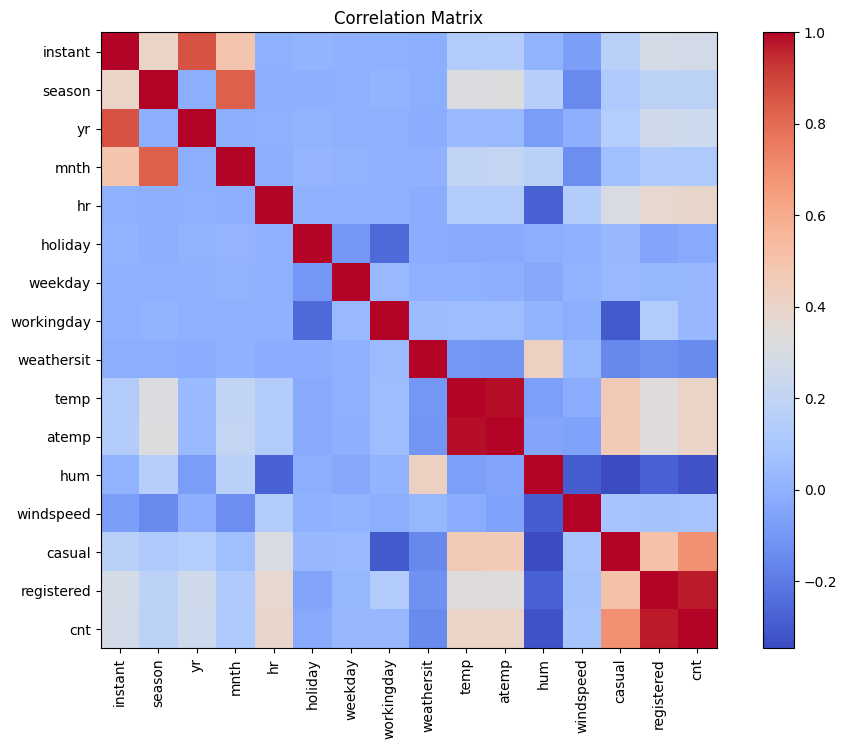

In [18]:
corr = df_hour.corr(numeric_only=True)

plt.figure(figsize=(12,8))

plt.imshow(corr, cmap="coolwarm")

plt.colorbar()

plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)

plt.yticks(range(len(corr.columns)), corr.columns)

plt.title("Correlation Matrix")

plt.show()

### Correlation Matrix Analysis
#### 1. Target Variable (cnt)

Focus on the last row/column (cnt).
<br>
Strong Positive Correlation<br>
registered → Very strong positive correlation (≈ 0.97)<br>
casual → Strong positive correlation (≈ 0.69)<br>
<br>
Reason
<br>
cnt = casual + registered
<br>
These two variables directly contribute to the target.<br>
Important: They must be removed before training because they cause data leakage.<br>

#### 2. Temperature

temp and atemp
<br>
Strong positive correlation with cnt<br>
Strong positive correlation with each other (≈0.99)<br>
<br>
This means
<br>
Warmer weather increases bike rentals.<br>
temp and atemp carry almost identical information.<br>
<br>
Observation<br>
Temperature is one of the most influential environmental factors affecting bike demand.

#### 3. Hour (hr)
Moderate positive correlation with cnt.
<br>
This makes sense because
<br>
Morning commute<br>
Evening commute<br>
generate higher rentals.

4. Weather Situation

weathersit....Negative correlation with cnt.
<br>
Meaning<br>
As weather becomes worse
<br>
Clear<br>
↓<br>
Mist<br>
↓<br>
Rain<br>
<br>
bike demand decreases.

#### 5. Humidity

hum....Shows a weak negative correlation.
<br>
Meaning
<br>
Higher humidity slightly reduces rentals.

#### 6. Windspeed

Very weak negative correlation.<br>
Meaning
<br>
Wind has only a small effect on bike demand.

#### 7. Holiday

Almost no correlation.
Meaning...
Holiday alone is not a strong predictor.
It becomes useful only when combined with
hour
weekday
weather
#### 8. Working Day

Weak positive correlation.
Demand is slightly higher on working days because many people commute.

#### 9. Season

Small to moderate positive correlation.
Demand changes with season because of weather.
<br>
The most important thing visible in this heatmap is
<br>
temp<br>
↓<br>
atemp<br>
<br>
These are almost perfectly correlated.<br>
This is called multicollinearity.
<br>
For tree-based models
<br>
Random Forest<br>
XGBoost<br>
LightGBM<br>
<br>
this is not a problem.
For Linear Regression,
we may keep only one of them or use Ridge/Lasso regularization.

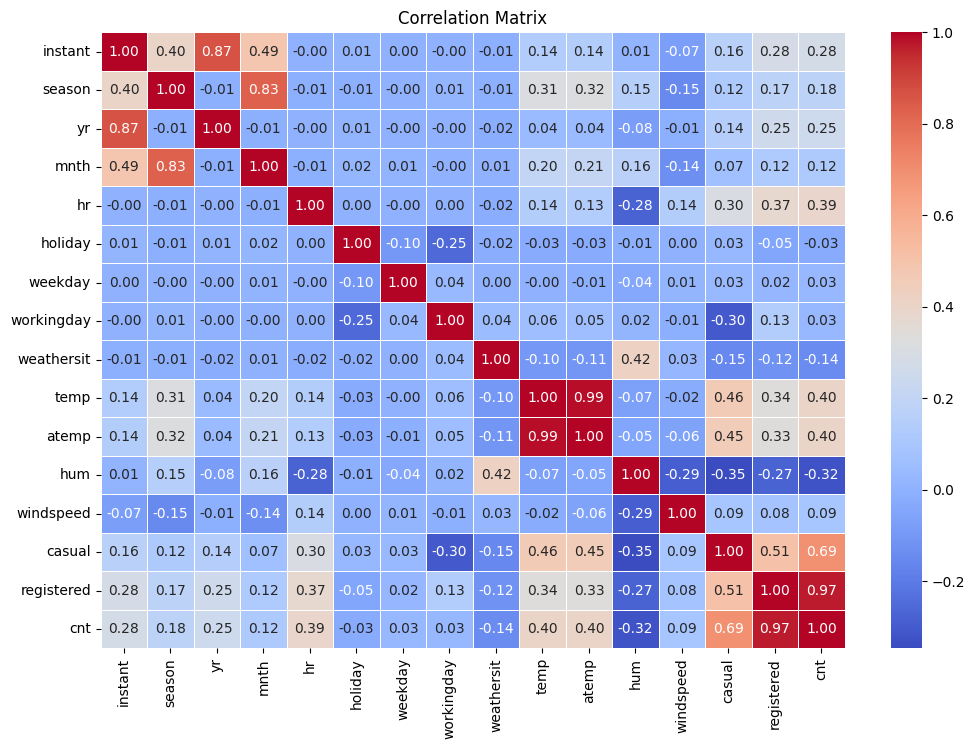

In [19]:
plt.figure(figsize=(12,8))

sns.heatmap(
    corr,
    annot=True,      # Show correlation values
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Matrix")
plt.show()

#### Correlation Matrix Analysis
Bike demand analysis indicates that registered and casual user metrics serve as primary demand predictors, though they act as data leakage, while temp and atemp exhibit strong positive correlations with higher rentals. Conversely, weathersit and humidity function as key demand inhibitors, with high humidity and poor weather significantly reducing bike usage.